# Magic-state brick-wall classifier

In [ ]:
import numpy as np
import pennylane as qml # pennylane==0.43.3

import matplotlib.pyplot as plt
from quantum_utils import spreading_matrix, UniformSpreading, initial_weights, particle_count, shift_coefficients

N_FEATURES = 8          # Change to 12
N_COLUMNS = 2           # Minimal useful brick-wall depth (ideally N_features)
K = None                # Even k; None uses the scalable default
READOUT = "sigmoid"     # "sigmoid" or "linear_score"
STEPS = 100
BATCH_SIZE = 8
Q_LR, H_LR = 0.5, 1.0

### From measurements to probability

For each input, the circuit measures one adjacent two-qubit projector per ring edge:

$$m_j = \langle |11\rangle\langle 11|_{j,j+1} \rangle.$$

With $n$ qubits, this gives $n$ quantum features. The notebook scales them as $f_j=4m_j$.
The classical readout computes $z=\mathbf{w}^T\mathbf{f}+b$. 

With `READOUT="sigmoid"`,
the probability of class 1 is $p(y=1|x)=\sigma(z)=1/(1+e^{-z})$.
The prediction is class 1 when $p\geq 0.5$. 

With `linear_score`, the sigmoid is omitted
and the sign of $z$ is used directly.

In [107]:
# Generate balanced, non-linearly separable XOR data.
def make_data(size, n, seed=0):
    rng = np.random.default_rng(seed)
    corners = np.tile([[-1, -1], [-1, 1], [1, -1], [1, 1]], (size // 4, 1))
    X = np.repeat(rng.uniform(-0.06, 0.06, (size // 4, n)), 4, axis=0)
    X[:, :2] += 0.20 * corners
    y = (corners[:, 0] != corners[:, 1]).astype(int)
    order = rng.permutation(size)
    return X[order], y[order]

In [108]:
# Build only the magic-state brick-wall circuit.
def make_circuit(n, columns=1, k=None):
    k = particle_count(n, k)
    spread = spreading_matrix(n)
    shape = (columns, 3 * n // 2)

    def pairs(col):
        out = [(j, j + 1) for j in range(col % 2, n - 1, 2)]
        return out + ([(n - 1, 0)] if col % 2 else [])

    @qml.qnode(qml.device("default.qubit", wires=n), interface=None, diff_method=None)
    def circuit(x, w):
        for block in range(k // 2):
            a, b, c, d = range(4 * block, 4 * block + 4)
            qml.X(a); qml.X(b); qml.Hadamard(c)
            for target in [d, a, b]: qml.CNOT(wires=[c, target])
        UniformSpreading(spread, wires=range(n))
        for j in range(n): qml.RZ(-np.pi * x[..., j], wires=j)
        for col in range(columns):
            for j in range(n): qml.RZ(-w[..., col, n // 2 + j], wires=j)
            for j, pair in enumerate(pairs(col)):
                qml.SingleExcitation(-2 * w[..., col, j], wires=pair)
        return tuple(qml.expval(qml.Projector([1, 1], wires=[j, (j + 1) % n])) for j in range(n))

    return circuit, shape, k

# Convert circuit outputs into batched quantum features.
def make_model(circuit, n):
    def features(X, w):
        c, b = len(w), len(X)
        xx, ww = np.tile(X, (c, 1)), np.repeat(w, b, axis=0)
        values = np.stack(circuit(xx, ww), axis=-1)
        return 4 * values.reshape(c, b, n)

    return features

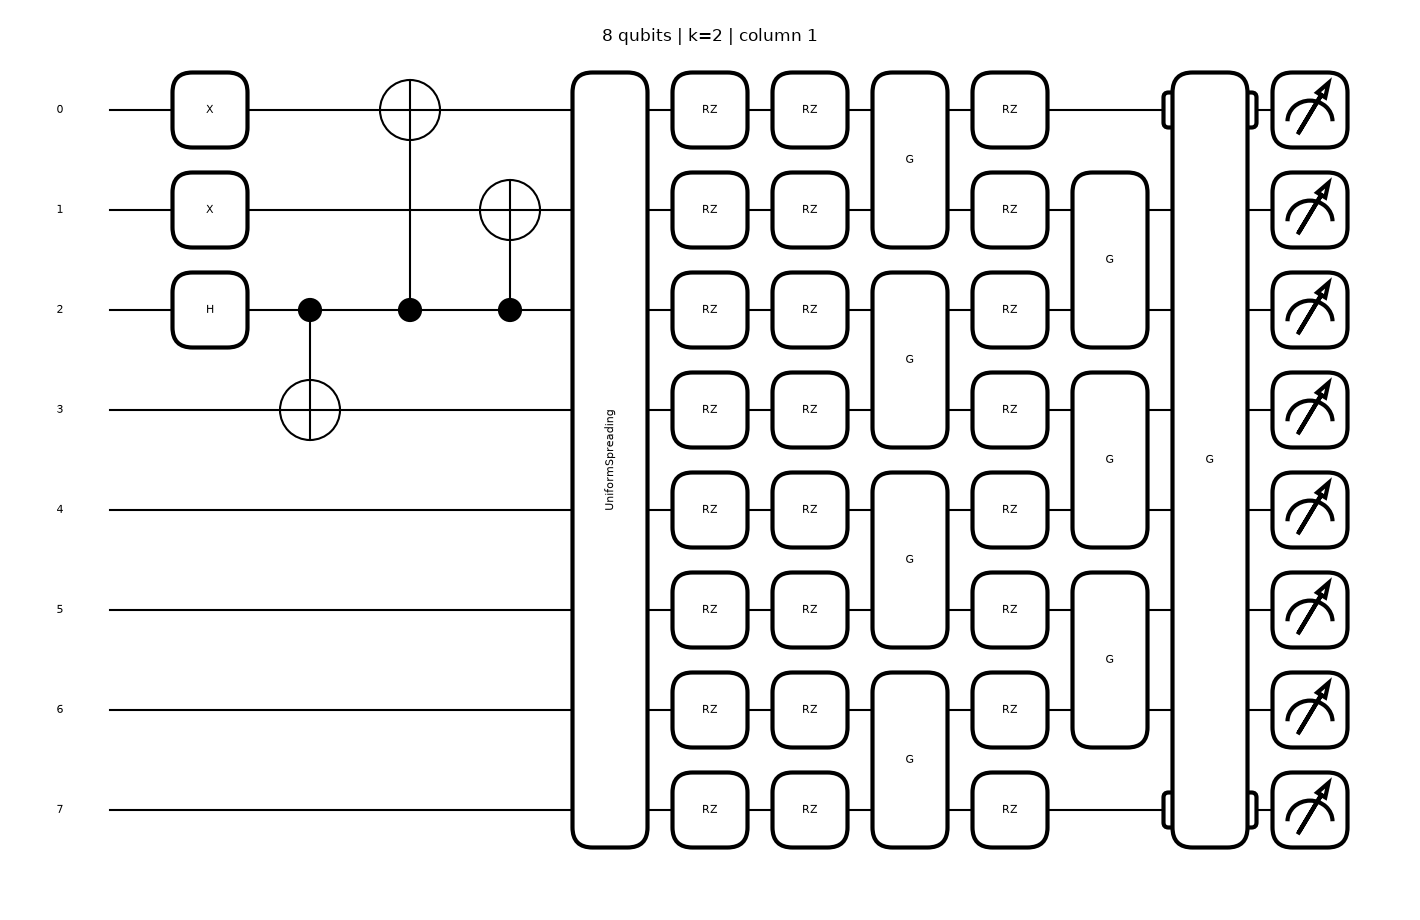

In [109]:
# Draw the circuit used by the model.
circuit, shape, k = make_circuit(N_FEATURES, N_COLUMNS, K)
parts = qml.draw_mpl(circuit, level="top", max_length=18, fontsize=8)(
    np.zeros(N_FEATURES), np.zeros(shape)
)
if not isinstance(parts, list):
    parts = [parts]
for number, (fig, ax) in enumerate(parts, 1):
    fig.suptitle(f"{N_FEATURES} qubits | k={k} | column {number}")
plt.show()

In [110]:
# Compute the selected classical readout and its loss.
def readout_loss(features, labels, head, mode):
    score = features @ head[:-1] + head[-1]
    if mode == "sigmoid":
        output = 1 / (1 + np.exp(-np.clip(score, -40, 40)))
        loss = np.mean(np.logaddexp(0, score) - labels * score)
        residual = (output - labels) / len(labels)
    else:
        loss = 0.5 * np.mean((score - (2 * labels - 1)) ** 2)
        residual = (score - (2 * labels - 1)) / len(labels)
    return loss, residual, score

In [111]:
# Train the quantum columns with the parallel parameter-shift rule.
def train(n, columns, k, mode, steps):
    rng = np.random.default_rng(42 + n)
    X, y = make_data(96, n, seed=42 + n)
    X_test, y_test = make_data(48, n, seed=142 + n)
    circuit, shape, k = make_circuit(n, columns, k)
    features = make_model(circuit, n)
    w, phases, _ = initial_weights(n, columns, rng)
    head = rng.normal(0, 0.1, n + 1)
    shifts, coeffs = shift_coefficients(k)
    history = []

    for step in range(steps):
        idx = np.concatenate([rng.choice(np.flatnonzero(y == c), BATCH_SIZE // 2, False) for c in [0, 1]])
        f = features(X[idx], w[None])[0]
        loss, residual, _ = readout_loss(f, y[idx], head, mode)
        history.append(loss)
        head -= H_LR * np.r_[f.T @ residual, residual.sum()]

        col = step % columns
        groups = [slice(0, n // 2), slice(n // 2, 3 * n // 2)]
        grad = np.zeros(shape[1])
        for group in groups:
            sign = rng.choice([-1., 1.], size=group.stop - group.start)
            shifted = []
            for shift in shifts:
                for direction in [1, -1]:
                    ww = w.copy(); ww[col, group] += direction * shift * sign; shifted.append(ww)
            values = features(X[idx], np.asarray(shifted)).reshape(len(shifts), 2, len(idx), n)
            derivative = np.einsum('q,qbh->bh', coeffs, values[:, 0] - values[:, 1])
            grad[group] = sign * np.sum((residual[:, None] * head[:-1]) * derivative)
        w[col] -= Q_LR * grad

    test_features = features(X_test, w[None])[0]
    _, _, score = readout_loss(test_features, y_test, head, mode)
    prediction = (score >= 0) if mode == "linear_score" else (score >= 0)
    return history, float(np.mean(prediction == y_test)), w, phases, k

features=8, k=2, readout=sigmoid, accuracy=72.9%


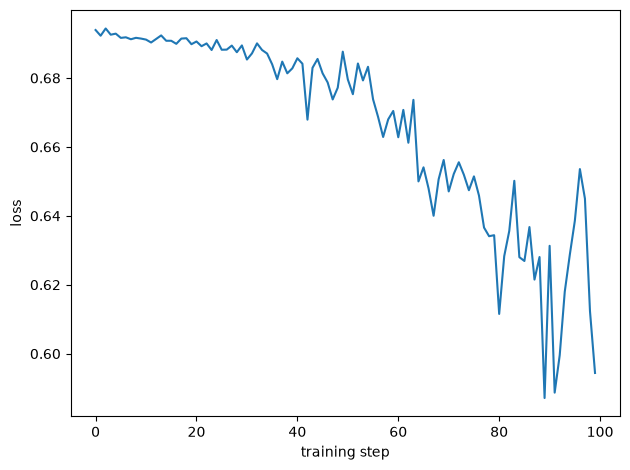

In [112]:
# Run training and show the loss and accuracy.
history, accuracy, weights, phases, k = train(N_FEATURES, N_COLUMNS, K, READOUT, STEPS)
print(f"features={N_FEATURES}, k={k}, readout={READOUT}, accuracy={accuracy:.1%}")
plt.plot(history)
plt.xlabel("training step")
plt.ylabel("loss")
plt.tight_layout()
plt.show()